# Tratamento de Dados — Pluviometria 2022 (Rio de Janeiro)

Notebook **focado em tratamento / limpeza de dados** de duas fontes de precipitação de 2022:

| Fonte | Pasta | Formato | Resolução |
|---|---|---|---|
| Rede de pluviômetros do **Sistema Alerta Rio** | `pluviometria_extraida/` | `.txt` de largura fixa, um arquivo por estação/mês | 15 min |
| Estações meteorológicas automáticas do **INMET** (4 estações) | `INMET/` | `.csv` com `;` e decimal `,` | horária |

**Roteiro:** ingestão → inspeção → limpeza → padronização → agregação → análise exploratória → engenharia de atributos → classificação (KNN e Árvore de Decisão).

**Tarefa de modelagem:** a partir das condições meteorológicas da hora atual (INMET), prever se **choverá na próxima hora**.

In [1]:
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.metrics import accuracy_score

# ---- utilitários de apoio (não alteram a proposta) ----
import re, io, warnings
from pathlib import Path

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# ============================================================================
# Localização da pasta "dados 2022" (deve conter INMET/ e pluviometria_extraida/)
# ----------------------------------------------------------------------------
# Se souber o caminho, escreva aqui e pule a busca automática. Exemplos:
#   Colab:   "/content/drive/MyDrive/PUC-Rio - BIA/3o período/ENG4040 - Projeto Integrado de Ciência de Dados/Dados_projeto/Pluviometricos/dados 2022"
#   Windows: r"G:\Meu Drive\PUC-Rio - BIA\3o período\ENG4040 - Projeto Integrado de Ciência de Dados\Dados_projeto\Pluviometricos\dados 2022"
DADOS_2022 = None
# ============================================================================

# No Google Colab, monta o Google Drive automaticamente
try:
    import google.colab  # noqa: F401
    if not Path("/content/drive/MyDrive").exists():
        from google.colab import drive
        drive.mount("/content/drive")
except ImportError:
    pass

_SUB = Path("PUC-Rio - BIA") / "3o período" / \
    "ENG4040 - Projeto Integrado de Ciência de Dados" / \
    "Dados_projeto" / "Pluviometricos" / "dados 2022"

_cands = []
if DADOS_2022:
    _cands.append(Path(DADOS_2022))
_cands += [
    Path.cwd(),
    Path.cwd() / "dados 2022",
    Path("/content/drive/MyDrive") / _SUB,
    Path.home() / "Google Drive" / _SUB,
    Path.home() / "GoogleDrive" / _SUB,
    Path(r"G:\Meu Drive") / _SUB,
]

def _ok(p):
    return (p / "INMET").is_dir() and (p / "pluviometria_extraida").is_dir()

BASE_DIR = next((p for p in _cands if _ok(p)), None)

# Último recurso: procurar por uma pasta chamada "dados 2022" dentro do Drive
if BASE_DIR is None and Path("/content/drive/MyDrive").exists():
    for p in Path("/content/drive/MyDrive").glob("**/dados 2022"):
        if _ok(p):
            BASE_DIR = p
            break

if BASE_DIR is None:
    raise FileNotFoundError(
        "Não encontrei a pasta 'dados 2022' com as subpastas INMET/ e "
        "pluviometria_extraida/.\nDefina DADOS_2022 manualmente no topo desta célula. "
        "Caminhos testados:\n  - " + "\n  - ".join(str(p) for p in _cands)
    )

PLV_DIR = BASE_DIR / "pluviometria_extraida"
INMET_DIR = BASE_DIR / "INMET"

plv_files = sorted(PLV_DIR.glob("*_Plv.txt"))
inmet_files = sorted(INMET_DIR.glob("INMET_*_2022.csv"))

print(f"Base: {BASE_DIR}")
print(f"{len(plv_files)} arquivos de pluviômetro | {len(inmet_files)} arquivos INMET")
assert plv_files and inmet_files, "Pasta encontrada, mas sem arquivos esperados dentro."
print("Exemplos:", [f.name for f in plv_files[:3]])

Mounted at /content/drive
Base: /content/drive/MyDrive/PUC-Rio - BIA/3o período/ENG4040 - Projeto Integrado de Ciência de Dados/Dados_projeto/Pluviometricos/dados 2022
384 arquivos de pluviômetro | 4 arquivos INMET
Exemplos: ['alto_da_boa_vista_202201_Plv.txt', 'alto_da_boa_vista_202202_Plv.txt', 'alto_da_boa_vista_202203_Plv.txt']


## Parte A — Rede de pluviômetros (Alerta Rio)

### A.1 Ingestão

Cada arquivo tem 5 linhas de cabeçalho/metadados e depois uma tabela de **largura fixa** com as colunas:
`Dia  Hora  HBV  15 min  01 h  04 h  24 h  96 h`.

- A coluna `HBV` vem sempre vazia → as linhas de dados têm 7 campos separados por espaços.
- Ausências são marcadas como `ND`.
- `15 min` é o incremento de chuva na janela; as demais são acumulados móveis (1 h, 4 h, 24 h, 96 h).

In [3]:
COLS_PLV = ["data", "hora", "p15min", "acum_1h", "acum_4h", "acum_24h", "acum_96h"]

def _ler_linhas(caminho):
    for enc in ("utf-8-sig", "latin-1"):
        try:
            return caminho.read_text(encoding=enc).splitlines(keepends=True)
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError("nao decodificou " + str(caminho))

def ler_pluviometro(caminho):
    """Lê um arquivo mensal de pluviômetro e devolve um DataFrame tidy."""
    linhas = _ler_linhas(caminho)
    # nome da estação a partir da 1a linha ('Relatório ... Estação: Copacabana')
    estacao_txt = linhas[0].split(":", 1)[-1].strip() if ":" in linhas[0] else caminho.stem
    # primeira linha de dados = primeira que começa com dd/mm/aaaa
    ini = next(i for i, l in enumerate(linhas) if re.match(r"\d{2}/\d{2}/\d{4}", l))
    df = pd.read_csv(
        io.StringIO("".join(linhas[ini:])),
        sep=r"\s+", header=None, names=COLS_PLV,
        engine="python", na_values=["ND", "nd", "-", ""],
    )
    # slug estável a partir do nome do arquivo: 'copacabana_202201_Plv.txt' -> 'copacabana'
    df.insert(0, "estacao", re.sub(r"_20\d{4}_Plv\.txt$", "", caminho.name))
    df["estacao_nome"] = estacao_txt
    df["arquivo"] = caminho.name
    return df

ler_pluviometro(plv_files[0]).head()

,estacao,data,hora,p15min,acum_1h,acum_4h,acum_24h,acum_96h,estacao_nome,arquivo
0,alto_da_boa_vista,01/01/2022,00:00:00,0.0,0.6,1.6,15.0,92.0,Alto da Boa Vista,alto_da_boa_vista_202201_Plv.txt
1,alto_da_boa_vista,01/01/2022,00:15:00,0.2,0.6,1.6,14.6,92.2,Alto da Boa Vista,alto_da_boa_vista_202201_Plv.txt
2,alto_da_boa_vista,01/01/2022,00:30:00,0.0,0.4,1.4,13.4,92.2,Alto da Boa Vista,alto_da_boa_vista_202201_Plv.txt
3,alto_da_boa_vista,01/01/2022,00:45:00,0.0,0.2,1.4,12.8,92.2,Alto da Boa Vista,alto_da_boa_vista_202201_Plv.txt
4,alto_da_boa_vista,01/01/2022,01:00:00,0.0,0.2,1.4,12.2,92.2,Alto da Boa Vista,alto_da_boa_vista_202201_Plv.txt


In [4]:
# Concatena todos os arquivos mensais/estações (pode levar ~1 min).
df_plv_raw = pd.concat((ler_pluviometro(f) for f in plv_files), ignore_index=True)
print("Formato bruto:", df_plv_raw.shape)
df_plv_raw.sample(6, random_state=RANDOM_STATE)

Formato bruto: (1075465, 10)


,estacao,data,hora,p15min,acum_1h,acum_4h,acum_24h,acum_96h,estacao_nome,arquivo
1066721,vidigal,01/10/2022,22:00:00,0.0,0.0,0.0,0.0,68.2,Vidigal,vidigal_202210_Plv.txt
890512,saude,19/06/2022,22:00:00,0.0,0.0,0.0,5.6,8.2,Saúde,saude_202206_Plv.txt
411543,guaratiba,17/04/2022,21:30:00,0.0,0.0,0.0,0.2,33.6,Guaratiba,guaratiba_202204_Plv.txt
358770,grande_meier,13/10/2022,20:15:00,0.0,0.0,0.0,0.0,0.0,Grande Méier,grande_meier_202210_Plv.txt
982687,tijuca,31/03/2022,17:30:00,0.0,0.0,0.0,1.8,2.0,Tijuca,tijuca_202203_Plv.txt
739772,rocinha,23/01/2022,08:15:00,0.0,0.0,0.0,0.0,0.0,Rocinha,rocinha_202201_Plv.txt


### A.2 Inspeção

In [5]:
df_plv_raw.info()
print("\nEstações (", df_plv_raw['estacao'].nunique(), "):", sorted(df_plv_raw['estacao'].unique()))
df_plv_raw.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1075465 entries, 0 to 1075464
Data columns (total 10 columns):
 #   Column        Non-Null Count    Dtype  
---  ------        --------------    -----  
 0   estacao       1075465 non-null  object 
 1   data          1075465 non-null  object 
 2   hora          1075465 non-null  object 
 3   p15min        1062894 non-null  float64
 4   acum_1h       1062793 non-null  float64
 5   acum_4h       1062242 non-null  float64
 6   acum_24h      1059667 non-null  float64
 7   acum_96h      1050692 non-null  float64
 8   estacao_nome  1075465 non-null  object 
 9   arquivo       1075465 non-null  object 
dtypes: float64(5), object(5)
memory usage: 82.1+ MB

Estações ( 32 ): ['alto_da_boa_vista', 'anchieta', 'av_brasil_mendanha', 'bangu', 'barrinha', 'campo_grande', 'cidade_de_deus', 'copacabana', 'grajau', 'grajau_jacarepagua', 'grande_meier', 'grota_funda', 'guaratiba', 'ilha_do_governador', 'iraja', 'jardim_botanico', 'laranjeiras', 'madureira

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
estacao,1075465,32,santa_cruz,35019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
data,1075465,365,19/12/2022,3072,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hora,1075465,96,06:00:00,11211,NaN,NaN,NaN,NaN,NaN,NaN,NaN
p15min,1062894.0,NaN,NaN,NaN,0.039876,0.385113,0.0,0.0,0.0,0.0,39.4
acum_1h,1062793.0,NaN,NaN,NaN,0.159543,1.236454,0.0,0.0,0.0,0.0,125.6
acum_4h,1062242.0,NaN,NaN,NaN,0.638415,3.552438,0.0,0.0,0.0,0.0,234.2
acum_24h,1059667.0,NaN,NaN,NaN,3.842783,12.337721,0.0,0.0,0.0,1.6,310.4
acum_96h,1050692.0,NaN,NaN,NaN,15.498867,29.255566,0.0,0.0,4.4,18.8,392.4
estacao_nome,1075465,32,Santa Cruz,35019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arquivo,1075465,384,urca_202207_Plv.txt,2976,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
chuva_cols = ["p15min", "acum_1h", "acum_4h", "acum_24h", "acum_96h"]
print("Valores ausentes por coluna:")
print(df_plv_raw.isna().sum())
print("\n% ausente nas colunas de chuva (marcadores 'ND' já viraram NaN):")
print((df_plv_raw[chuva_cols].isna().mean() * 100).round(2))

Valores ausentes por coluna:
estacao             0
data                0
hora                0
p15min          12571
acum_1h         12672
acum_4h         13223
acum_24h        15798
acum_96h        24773
estacao_nome        0
arquivo             0
dtype: int64

% ausente nas colunas de chuva (marcadores 'ND' já viraram NaN):
p15min      1.17
acum_1h     1.18
acum_4h     1.23
acum_24h    1.47
acum_96h    2.30
dtype: float64


### A.3 Limpeza

1. `data` + `hora` → `datahora` (`datetime`); linhas com data inválida são descartadas.
2. Colunas de chuva convertidas para `float`.
3. Duplicatas por (`estacao`, `datahora`) removidas; ordenação cronológica.
4. Valores **negativos** (impossíveis) → `NaN`.
5. Outliers físicos em 15 min (`> 50 mm`) sinalizados em `outlier_p15min`.

In [ ]:
plv = df_plv_raw.copy()

# 1) datetime
plv["datahora"] = pd.to_datetime(
    plv["data"].str.strip() + " " + plv["hora"].str.strip(),
    format="%d/%m/%Y %H:%M:%S", errors="coerce",
)
print("Linhas com data/hora inválida (descartadas):", int(plv["datahora"].isna().sum()))
plv = plv.dropna(subset=["datahora"])

# 2) tipos numéricos
plv[chuva_cols] = plv[chuva_cols].apply(pd.to_numeric, errors="coerce")

# 3) duplicatas + ordenação
antes = len(plv)
plv = plv.drop_duplicates(subset=["estacao", "datahora"]).sort_values(["estacao", "datahora"])
print("Duplicatas (estação+instante) removidas:", antes - len(plv))

# 4) negativos -> NaN
neg = int((plv[chuva_cols] < 0).sum().sum())
plv[chuva_cols] = plv[chuva_cols].mask(plv[chuva_cols] < 0)
print("Células negativas convertidas para NaN:", neg)

# 5) outliers físicos em 15 min
LIM_15 = 50.0
plv["outlier_p15min"] = plv["p15min"] > LIM_15
print(f"Registros com p15min > {LIM_15} mm marcados como outlier:", int(plv["outlier_p15min"].sum()))

plv = plv.drop(columns=["data", "hora"])
plv.head()

Linhas com data/hora inválida (descartadas): 0


### A.4 Cobertura temporal por estação

Compara o número de registros observados com o número de passos de 15 min esperados entre o primeiro e o último instante de cada estação.

In [ ]:
cobertura = plv.groupby("estacao").agg(
    inicio=("datahora", "min"),
    fim=("datahora", "max"),
    registros=("datahora", "size"),
    p15min_ausente=("p15min", lambda s: int(s.isna().sum())),
)
cobertura["passos_esperados"] = (
    (cobertura["fim"] - cobertura["inicio"]).dt.total_seconds() // 900 + 1
).astype(int)
cobertura["completude_%"] = (100 * cobertura["registros"] / cobertura["passos_esperados"]).round(1)
cobertura.sort_values("completude_%")

### A.5 Agregações (diária e mensal)

A chuva diária/mensal é reconstruída somando os **incrementos de 15 min** (`p15min`). `min_count=1` evita transformar dias inteiros sem dado em zero.

In [ ]:
plv_idx = plv.set_index("datahora")

chuva_diaria = (
    plv_idx.groupby("estacao")["p15min"]
    .resample("D").sum(min_count=1)
    .rename("chuva_mm")
    .reset_index()
)
chuva_diaria["ano_mes"] = chuva_diaria["datahora"].dt.to_period("M").astype(str)

chuva_mensal = (
    chuva_diaria.groupby(["estacao", "ano_mes"])["chuva_mm"].sum(min_count=1).reset_index()
)
tabela_mensal = chuva_mensal.pivot(index="estacao", columns="ano_mes", values="chuva_mm").round(1)
print("Chuva mensal por estação (mm):")
tabela_mensal

In [ ]:
resumo_estacao = (
    chuva_diaria.groupby("estacao")["chuva_mm"].agg(
        total_ano_mm="sum",
        dias_com_chuva=lambda s: int((s > 0).sum()),
        dia_mais_chuvoso_mm="max",
        media_diaria_mm="mean",
    )
    .round(2)
    .sort_values("total_ano_mm", ascending=False)
)
resumo_estacao

### A.6 Análise exploratória

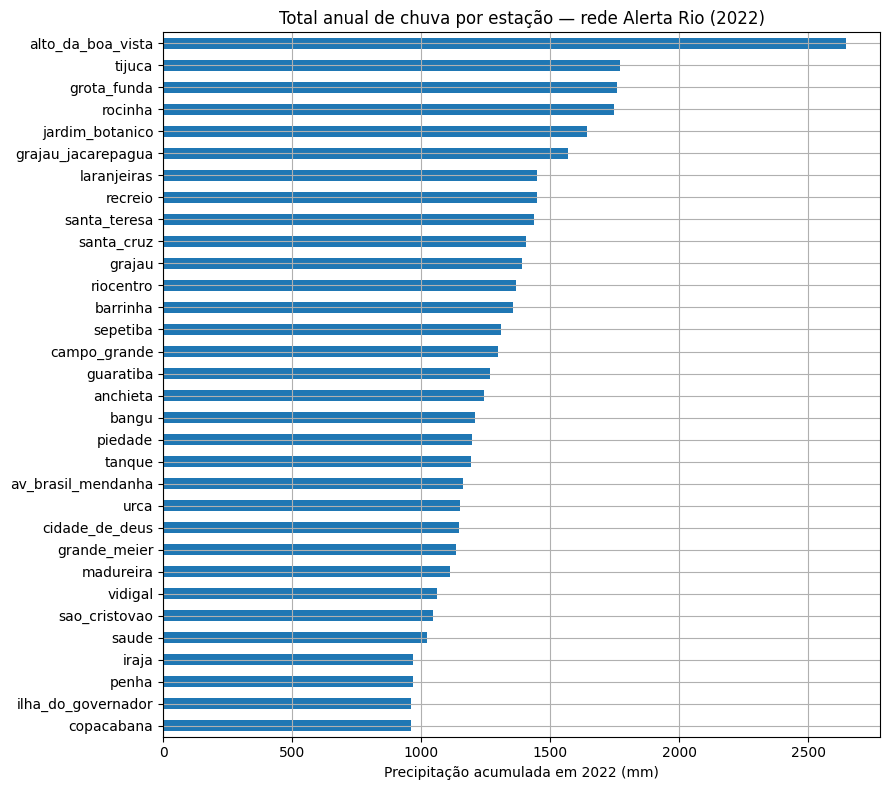

In [ ]:
ax = resumo_estacao["total_ano_mm"].plot(kind="barh", figsize=(9, 8))
ax.set_xlabel("Precipitação acumulada em 2022 (mm)")
ax.set_ylabel("")
ax.set_title("Total anual de chuva por estação — rede Alerta Rio (2022)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

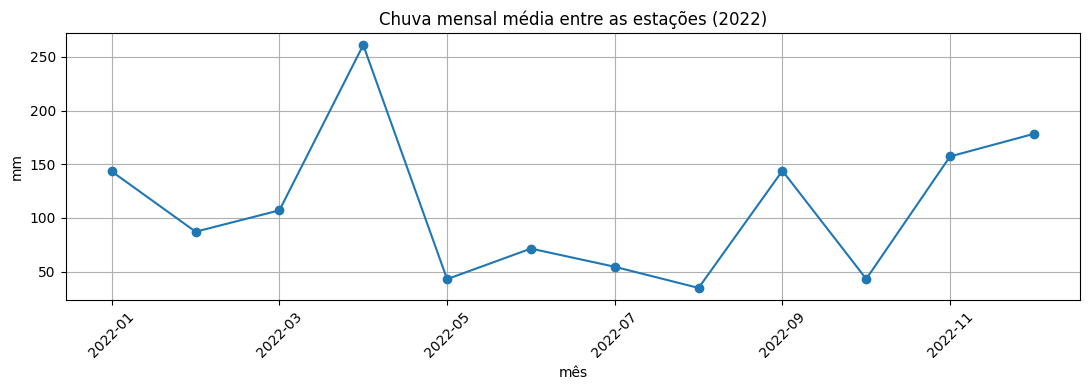

In [ ]:
ordem = [f"2022-{m:02d}" for m in range(1, 13)]
perfil_mensal = chuva_mensal.groupby("ano_mes")["chuva_mm"].mean().reindex(ordem)
ax = perfil_mensal.plot(marker="o")
ax.set_title("Chuva mensal média entre as estações (2022)")
ax.set_ylabel("mm")
ax.set_xlabel("mês")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

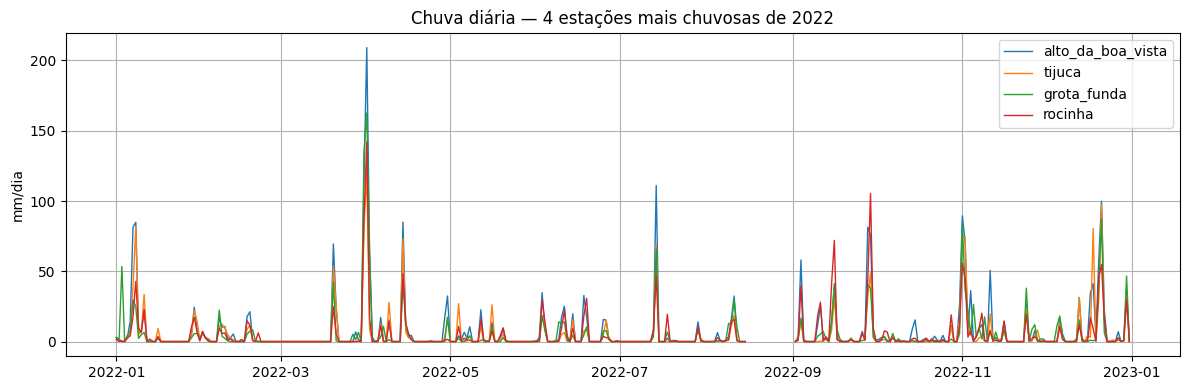

In [ ]:
destaque = resumo_estacao.head(4).index.tolist()
fig, ax = plt.subplots(figsize=(12, 4))
for est in destaque:
    s = chuva_diaria[chuva_diaria["estacao"] == est].set_index("datahora")["chuva_mm"]
    ax.plot(s.index, s.values, label=est, lw=1)
ax.set_title("Chuva diária — 4 estações mais chuvosas de 2022")
ax.set_ylabel("mm/dia")
ax.legend()
plt.tight_layout()
plt.show()

## Parte B — Estações INMET

### B.1 Ingestão e limpeza

Arquivos `.csv` com `;` como separador, `,` como decimal e BOM UTF-8. Campos vazios = medida ausente.

In [ ]:
REN_INMET = {
    "Data": "data", "Hora (UTC)": "hora_utc",
    "Temp. Ins. (C)": "temp", "Temp. Max. (C)": "temp_max", "Temp. Min. (C)": "temp_min",
    "Umi. Ins. (%)": "umid", "Umi. Max. (%)": "umid_max", "Umi. Min. (%)": "umid_min",
    "Pto Orvalho Ins. (C)": "orvalho", "Pto Orvalho Max. (C)": "orvalho_max",
    "Pto Orvalho Min. (C)": "orvalho_min",
    "Pressao Ins. (hPa)": "pressao", "Pressao Max. (hPa)": "pressao_max",
    "Pressao Min. (hPa)": "pressao_min",
    "Vel. Vento (m/s)": "vento", "Dir. Vento (m/s)": "vento_dir", "Raj. Vento (m/s)": "vento_rajada",
    "Chuva (mm)": "chuva",
}

def ler_inmet(caminho):
    df = pd.read_csv(caminho, sep=";", decimal=",", encoding="utf-8-sig")
    rad = [c for c in df.columns if c.startswith("Radiacao")][0]
    df = df.rename(columns={**REN_INMET, rad: "radiacao"})
    df["estacao"] = caminho.stem.split("_")[1]  # INMET_A652_2022 -> A652
    df["datahora"] = pd.to_datetime(
        df["data"] + df["hora_utc"].astype(int).map(lambda h: f"{h:04d}"),
        format="%d/%m/%Y%H%M", errors="coerce",
    )
    return df.drop(columns=["data", "hora_utc"])

df_inmet_raw = pd.concat((ler_inmet(f) for f in inmet_files), ignore_index=True)
print("Formato bruto INMET:", df_inmet_raw.shape)
df_inmet_raw.head()

Formato bruto INMET: (35040, 19)


,temp,temp_max,temp_min,umid,umid_max,umid_min,orvalho,orvalho_max,orvalho_min,pressao,pressao_max,pressao_min,vento,vento_dir,vento_rajada,radiacao,chuva,estacao,datahora
0,23.1,23.3,22.9,100.0,100.0,100.0,23.1,23.3,22.9,1007.4,1007.4,1006.7,1.5,334.0,2.3,NaN,0.0,A602,2022-01-01 00:00:00
1,23.0,23.2,22.7,NaN,NaN,NaN,NaN,NaN,NaN,1007.8,1007.9,1007.4,0.8,359.0,2.0,NaN,0.2,A602,2022-01-01 01:00:00
2,22.9,23.3,22.8,NaN,NaN,NaN,NaN,NaN,NaN,1007.6,1007.9,1007.6,0.3,136.0,1.8,NaN,0.0,A602,2022-01-01 02:00:00
3,23.3,23.3,22.8,100.0,NaN,NaN,23.3,NaN,NaN,1006.7,1007.6,1006.7,1.9,133.0,3.0,NaN,0.0,A602,2022-01-01 03:00:00
4,23.1,23.4,22.9,100.0,100.0,100.0,23.1,23.4,22.9,1006.7,1006.7,1006.5,3.0,282.0,4.2,1.0,0.0,A602,2022-01-01 04:00:00


In [ ]:
print("Ausentes por coluna (%):")
print((df_inmet_raw.isna().mean() * 100).round(1).sort_values(ascending=False))
print("\nRegistros por estação (8760 = ano horário completo):")
print(df_inmet_raw["estacao"].value_counts())

Ausentes por coluna (%):
radiacao        42.0
umid_min        15.7
orvalho_min     15.7
orvalho         15.6
orvalho_max     15.6
umid            15.6
umid_max        15.6
vento_rajada     1.5
vento_dir        1.4
vento            1.4
temp             0.2
temp_min         0.2
temp_max         0.2
pressao_max      0.2
pressao          0.2
pressao_min      0.2
chuva            0.2
estacao          0.0
datahora         0.0
dtype: float64

Registros por estação (8760 = ano horário completo):
estacao
A602    8760
A621    8760
A636    8760
A652    8760
Name: count, dtype: int64


In [ ]:
inmet = df_inmet_raw.copy()

# 1) faixas fisicamente válidas -> fora da faixa vira NaN
faixas = {
    "temp": (-5, 50), "temp_max": (-5, 50), "temp_min": (-5, 50),
    "umid": (0, 100), "umid_max": (0, 100), "umid_min": (0, 100),
    "orvalho": (-10, 35), "orvalho_max": (-10, 35), "orvalho_min": (-10, 35),
    "pressao": (900, 1050), "pressao_max": (900, 1050), "pressao_min": (900, 1050),
    "vento": (0, 60), "vento_rajada": (0, 100), "vento_dir": (0, 360),
    "radiacao": (0, 6000), "chuva": (0, 150),
}
for col, (lo, hi) in faixas.items():
    fora = int(((inmet[col] < lo) | (inmet[col] > hi)).sum())
    if fora:
        print(f"{col}: {fora} valores fora de [{lo}, {hi}] -> NaN")
    inmet[col] = inmet[col].where(inmet[col].between(lo, hi))

# 2) duplicatas / ordenação / datas válidas
inmet = (
    inmet.dropna(subset=["datahora"])
    .drop_duplicates(subset=["estacao", "datahora"])
    .sort_values(["estacao", "datahora"])
    .reset_index(drop=True)
)

# 3) tratamentos de domínio
inmet["radiacao"] = inmet["radiacao"].fillna(0.0)  # ausente à noite = sem radiação solar
inmet["chuva"] = inmet["chuva"].fillna(0.0)         # sem registro da báscula = sem chuva medida

# 4) variáveis meteorológicas: interpolação temporal curta por estação
met_cols = ["temp", "umid", "orvalho", "pressao", "vento", "vento_rajada"]
inmet[met_cols] = inmet.groupby("estacao")[met_cols].transform(
    lambda s: s.interpolate(limit=3).ffill(limit=2).bfill(limit=2)
)

print("\nAusentes após limpeza (%):")
print((inmet[met_cols + ["radiacao", "chuva"]].isna().mean() * 100).round(2))
inmet.head()


Ausentes após limpeza (%):
temp             0.06
umid            14.61
orvalho         14.66
pressao          0.07
vento            0.71
vento_rajada     0.84
radiacao         0.00
chuva            0.00
dtype: float64


,temp,temp_max,temp_min,umid,umid_max,umid_min,orvalho,orvalho_max,orvalho_min,pressao,pressao_max,pressao_min,vento,vento_dir,vento_rajada,radiacao,chuva,estacao,datahora
0,23.1,23.3,22.9,100.0,100.0,100.0,23.100000,23.3,22.9,1007.4,1007.4,1006.7,1.5,334.0,2.3,0.0,0.0,A602,2022-01-01 00:00:00
1,23.0,23.2,22.7,100.0,NaN,NaN,23.166667,NaN,NaN,1007.8,1007.9,1007.4,0.8,359.0,2.0,0.0,0.2,A602,2022-01-01 01:00:00
2,22.9,23.3,22.8,100.0,NaN,NaN,23.233333,NaN,NaN,1007.6,1007.9,1007.6,0.3,136.0,1.8,0.0,0.0,A602,2022-01-01 02:00:00
3,23.3,23.3,22.8,100.0,NaN,NaN,23.300000,NaN,NaN,1006.7,1007.6,1006.7,1.9,133.0,3.0,0.0,0.0,A602,2022-01-01 03:00:00
4,23.1,23.4,22.9,100.0,100.0,100.0,23.100000,23.4,22.9,1006.7,1006.7,1006.5,3.0,282.0,4.2,1.0,0.0,A602,2022-01-01 04:00:00


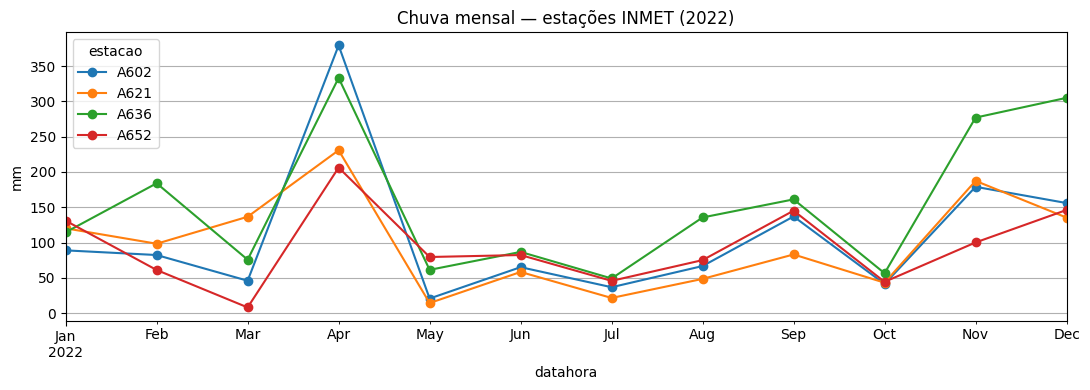

estacao,A602,A621,A636,A652
datahora,,,,
2022-01-01,89.0,120.2,114.6,131.0
2022-02-01,82.4,98.4,184.0,61.2
2022-03-01,46.0,136.6,75.8,8.2
2022-04-01,379.2,230.8,333.2,206.2
2022-05-01,20.8,14.4,61.4,79.6
2022-06-01,65.2,58.4,86.8,82.4
2022-07-01,36.8,21.6,49.2,45.8
2022-08-01,66.8,48.6,135.6,75.2
2022-09-01,137.0,83.2,161.2,145.2


In [ ]:
inmet_mensal = (
    inmet.set_index("datahora").groupby("estacao")["chuva"]
    .resample("MS").sum().rename("chuva_mm").reset_index()
)
piv = inmet_mensal.pivot(index="datahora", columns="estacao", values="chuva_mm")
ax = piv.plot(marker="o")
ax.set_title("Chuva mensal — estações INMET (2022)")
ax.set_ylabel("mm")
plt.tight_layout()
plt.show()
piv.round(1)

## Parte C — Engenharia de atributos para a classificação

**Alvo:** `alvo = 1` se `chuva` da **próxima hora** `> 0`, senão `0`.

**Atributos (hora atual):** temperatura, umidade, ponto de orvalho, pressão, vento, rajada, radiação, spread T–Td (proxy de saturação), chuva atual, chuva nas 3 h anteriores, tendências de 3 h (pressão, umidade, temperatura) e codificação cíclica de hora e mês.

In [ ]:
df = inmet.sort_values(["estacao", "datahora"]).copy()
g = df.groupby("estacao")

# tendências nas últimas 3 h (por estação)
df["pressao_tend3h"] = g["pressao"].transform(lambda s: s - s.shift(3))
df["umid_tend3h"] = g["umid"].transform(lambda s: s - s.shift(3))
df["temp_tend3h"] = g["temp"].transform(lambda s: s - s.shift(3))

# chuva acumulada nas 3 h anteriores e spread T-Td
df["chuva_3h"] = g["chuva"].transform(lambda s: s.rolling(3).sum())
df["spread_t_td"] = df["temp"] - df["orvalho"]

# sazonalidade / ciclo diário (codificação cíclica)
hora = df["datahora"].dt.hour
mes = df["datahora"].dt.month
df["hora_sin"] = np.sin(2 * np.pi * hora / 24)
df["hora_cos"] = np.cos(2 * np.pi * hora / 24)
df["mes_sin"] = np.sin(2 * np.pi * mes / 12)
df["mes_cos"] = np.cos(2 * np.pi * mes / 12)

# ALVO: chuva na próxima hora
df["chuva_prox"] = g["chuva"].transform(lambda s: s.shift(-1))
df = df.dropna(subset=["chuva_prox"])
df["alvo"] = (df["chuva_prox"] > 0).astype(int)

FEATURES = [
    "temp", "umid", "orvalho", "pressao", "vento", "vento_rajada", "radiacao",
    "spread_t_td", "chuva", "chuva_3h",
    "pressao_tend3h", "umid_tend3h", "temp_tend3h",
    "hora_sin", "hora_cos", "mes_sin", "mes_cos",
]

dados = df.dropna(subset=FEATURES + ["alvo"]).reset_index(drop=True)
print("Amostras utilizáveis:", len(dados))
print("\nDistribuição do alvo (0 = sem chuva / 1 = chuva na próxima hora):")
print(dados["alvo"].value_counts(normalize=True).round(3))
dados[FEATURES + ["alvo"]].head()

Amostras utilizáveis: 29539

Distribuição do alvo (0 = sem chuva / 1 = chuva na próxima hora):
alvo
0    0.912
1    0.088
Name: proportion, dtype: float64


,temp,umid,orvalho,pressao,vento,vento_rajada,radiacao,spread_t_td,chuva,chuva_3h,pressao_tend3h,umid_tend3h,temp_tend3h,hora_sin,hora_cos,mes_sin,mes_cos,alvo
0,23.3,100.0,23.300000,1006.7,1.9,3.0,0.0,0.000000,0.0,0.2,-0.7,0.0,0.2,0.707107,7.071068e-01,0.5,0.866025,0
1,23.1,100.0,23.100000,1006.7,3.0,4.2,1.0,0.000000,0.0,0.0,-1.1,0.0,0.1,0.866025,5.000000e-01,0.5,0.866025,1
2,22.8,100.0,22.800000,1006.6,1.8,4.6,0.0,0.000000,0.6,0.6,-1.0,0.0,-0.1,0.965926,2.588190e-01,0.5,0.866025,0
3,22.4,100.0,22.400000,1006.4,2.0,3.3,0.0,0.000000,0.0,0.6,-0.3,0.0,-0.9,1.000000,6.123234e-17,0.5,0.866025,1
4,22.1,100.0,23.085714,1006.2,2.2,3.7,0.0,-0.985714,1.2,1.8,-0.5,0.0,-1.0,0.965926,-2.588190e-01,0.5,0.866025,1


### C.1 Separação treino/teste e padronização

A padronização (z-score) usa **apenas** média/desvio do treino, evitando vazamento de informação. O KNN usa os dados padronizados; a árvore não precisa.

In [ ]:
X = dados[FEATURES].to_numpy(dtype=float)
y = dados["alvo"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

media = X_train.mean(axis=0)
desvio = X_train.std(axis=0)
desvio[desvio == 0] = 1.0
X_train_z = (X_train - media) / desvio
X_test_z = (X_test - media) / desvio

print("Treino:", X_train_z.shape, "| Teste:", X_test_z.shape)

Treino: (22154, 17) | Teste: (7385, 17)


## Parte D — Classificação

### D.1 Linha de base (classe majoritária)

In [ ]:
classe_maj = np.bincount(y_train).argmax()
acc_base = accuracy_score(y_test, np.full_like(y_test, classe_maj))
print(f"Baseline (prever sempre classe {classe_maj}): acurácia = {acc_base:.3f}")

Baseline (prever sempre classe 0): acurácia = 0.912


### D.2 K-Nearest Neighbors

In [ ]:
print("Busca simples de k:")
for k in [5, 15, 31, 51, 75]:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_train_z, y_train)
    print(f"  k = {k:>3} -> acurácia = {accuracy_score(y_test, m.predict(X_test_z)):.3f}")

knn = KNeighborsClassifier(n_neighbors=31)
knn.fit(X_train_z, y_train)
pred_knn = knn.predict(X_test_z)
print("\nKNN (k=31) — acurácia:", round(accuracy_score(y_test, pred_knn), 3))
print(pd.crosstab(pd.Series(y_test, name="real"), pd.Series(pred_knn, name="previsto")))

### D.3 Árvore de Decisão

`class_weight="balanced"` compensa o desbalanceamento do alvo (a maioria das horas não tem chuva).

In [ ]:
print("Busca simples de profundidade:")
for d in [3, 4, 5, 8, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE, class_weight="balanced")
    m.fit(X_train, y_train)
    print(f"  max_depth = {str(d):>4} -> acurácia = {accuracy_score(y_test, m.predict(X_test)):.3f}")

arvore = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE, class_weight="balanced")
arvore.fit(X_train, y_train)
pred_arv = arvore.predict(X_test)
print("\nÁrvore (max_depth=4) — acurácia:", round(accuracy_score(y_test, pred_arv), 3))
print(pd.crosstab(pd.Series(y_test, name="real"), pd.Series(pred_arv, name="previsto")))

In [ ]:
plt.figure(figsize=(20, 9))
plot_tree(
    arvore, feature_names=FEATURES, class_names=["sem chuva", "chuva"],
    filled=True, rounded=True, fontsize=8, impurity=False, proportion=True,
)
plt.title("Árvore de Decisão (max_depth=4) — chuva na próxima hora")
plt.tight_layout()
plt.show()

In [ ]:
imp = pd.Series(arvore.feature_importances_, index=FEATURES).sort_values()
ax = imp.plot(kind="barh", figsize=(8, 6))
ax.set_title("Importância dos atributos — Árvore de Decisão")
ax.set_xlabel("importância (redução de Gini)")
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).round(3)

## Parte E — Integração mensal (pluviometria × INMET): manter só colunas de chuva

Carrega a tabela integrada `integrado_mensal_plv_x_inmet.csv` (uma linha por estação pluviométrica e mês, com o contexto meteorológico do INMET no mesmo mês) e mantém **somente as colunas cujo nome contém a palavra `chuva`**. Todas as outras — temperatura, umidade, pressão, orvalho, vento, radiação e também as chaves `estacao` / `ano_mes` — são descartadas.

> Para preservar `estacao` e `ano_mes` junto das colunas de chuva, mude `MANTER_CHAVES = True` na célula abaixo.

In [ ]:
MANTER_CHAVES = False   # True -> preserva 'estacao' e 'ano_mes' junto das colunas de chuva

# --- localiza o CSV integrado ---------------------------------------------------
_nome = "integrado_mensal_plv_x_inmet.csv"
try:
    PROJ_DIR = BASE_DIR.parents[2]      # .../ENG4040 - Projeto Integrado de Ciência de Dados
except Exception:
    PROJ_DIR = Path.cwd()

_cands_integ = [
    PROJ_DIR / "Dados_tratados" / _nome,
    BASE_DIR / _nome,
    Path.cwd() / _nome,
    Path.cwd().parent / "Dados_tratados" / _nome,
]
caminho_integ = next((p for p in _cands_integ if p.exists()), None)

if caminho_integ is None:                # último recurso: busca recursiva
    for _raiz in {PROJ_DIR, Path.cwd(), Path("/content/drive/MyDrive")}:
        if _raiz.exists():
            _achou = list(_raiz.glob(f"**/{_nome}"))
            if _achou:
                caminho_integ = _achou[0]
                break

if caminho_integ is None:
    raise FileNotFoundError(
        f"{_nome} não encontrado. Caminhos testados:\n  - "
        + "\n  - ".join(str(p) for p in _cands_integ)
    )

# --- carrega e filtra colunas -------------------------------------------------
integrado = pd.read_csv(caminho_integ)
print("Arquivo:", caminho_integ)
print("Colunas originais:", list(integrado.columns))

colunas_chuva = [c for c in integrado.columns if "chuva" in c.lower()]
selecao = colunas_chuva.copy()
if MANTER_CHAVES:
    selecao = [c for c in ["estacao", "ano_mes"] if c in integrado.columns] + selecao

integrado_chuva = integrado[selecao].copy()

print("\nColunas mantidas:", list(integrado_chuva.columns))
print("Colunas removidas:", [c for c in integrado.columns if c not in integrado_chuva.columns])
print("Formato final:", integrado_chuva.shape)

# --- salva o resultado ao lado do arquivo de origem -------------------------
saida = caminho_integ.with_name("integrado_mensal_apenas_chuva.csv")
integrado_chuva.to_csv(saida, index=False, encoding="utf-8-sig")
print("Salvo em:", saida)

integrado_chuva.head(10)

## Parte F — Remover o contexto meteorológico do INMET

Parte da tabela integrada `integrado_mensal_plv_x_inmet.csv` e descarta as colunas de **contexto meteorológico da cidade** (temperatura, umidade, orvalho, pressão, vento, radiação e as contagens de horas), mantendo apenas as chaves e as colunas de chuva:
`estacao`, `ano_mes`, `plv_chuva_mm`, `inmet_cidade_chuva_mm`, `inmet_chuva_mm_A602/A621/A636/A652`.

In [ ]:
# colunas de contexto meteorológico do INMET a descartar
COLS_REMOVER = [
    "inmet_cidade_horas_com_chuva",
    "inmet_cidade_temp_media_c",
    "inmet_cidade_temp_max_c",
    "inmet_cidade_temp_min_c",
    "inmet_cidade_umid_media_pct",
    "inmet_cidade_orvalho_media_c",
    "inmet_cidade_pressao_media_hpa",
    "inmet_cidade_vento_media_ms",
    "inmet_cidade_vento_rajada_max_ms",
    "inmet_cidade_radiacao_MJm2_total",
    "inmet_cidade_horas_validas",
]

# usa 'integrado' se já foi carregado na Parte E; senão, lê o CSV
if "integrado" not in globals():
    _nome = "integrado_mensal_plv_x_inmet.csv"
    try:
        PROJ_DIR = BASE_DIR.parents[2]
    except Exception:
        PROJ_DIR = Path.cwd()
    _cands = [PROJ_DIR / "Dados_tratados" / _nome, Path.cwd() / _nome,
              Path.cwd().parent / "Dados_tratados" / _nome]
    _p = next((p for p in _cands if p.exists()), None)
    if _p is None:
        for _raiz in {PROJ_DIR, Path.cwd(), Path("/content/drive/MyDrive")}:
            if _raiz.exists():
                _achou = list(_raiz.glob(f"**/{_nome}"))
                if _achou:
                    _p = _achou[0]
                    break
    if _p is None:
        raise FileNotFoundError(f"{_nome} não encontrado.")
    integrado = pd.read_csv(_p)
    caminho_integ = _p

_faltando = [c for c in COLS_REMOVER if c not in integrado.columns]
if _faltando:
    print("Aviso: já não estavam na tabela ->", _faltando)

integrado_sem_contexto = integrado.drop(columns=[c for c in COLS_REMOVER if c in integrado.columns])

print("Colunas removidas:", [c for c in COLS_REMOVER if c in integrado.columns])
print("Colunas mantidas :", list(integrado_sem_contexto.columns))
print("Formato final    :", integrado_sem_contexto.shape)

saida = caminho_integ.with_name("integrado_mensal_sem_contexto_inmet.csv")
integrado_sem_contexto.to_csv(saida, index=False, encoding="utf-8-sig")
print("Salvo em:", saida)

integrado_sem_contexto.head(10)

## Parte G — Integrar o `codbairro` do censo

Vincula cada estação pluviométrica do Alerta Rio a um bairro do Rio de Janeiro e traz o `codbairro` (e `bairro`, `regiao_adm`) de `censo_bairros_tratado.csv` para a tabela integrada mensal.

O dicionário `ESTACAO_BAIRRO` faz o de-para `estacao → bairro_norm`. A maioria é direta (mesmo nome); algumas são **aproximações**, porque a estação cobre uma área e não um bairro único:

| Estação | Bairro adotado | Motivo |
|---|---|---|
| `av_brasil_mendanha` | Campo Grande | estação na Av. Brasil, altura de Mendanha |
| `barrinha` | Recreio dos Bandeirantes | Barrinha fica no Recreio |
| `grajau_jacarepagua` | Jacarepaguá | estação Grajaú/Jacarepaguá |
| `grande_meier` | Méier | "Grande Méier" é um conjunto de bairros |
| `grota_funda` | Guaratiba | Estrada da Grota Funda |
| `ilha_do_governador` | Jardim Guanabara | bairro central da Ilha |
| `riocentro` | Jacarepaguá | o Riocentro fica em Jacarepaguá |

Ajuste o dicionário se quiser outro critério. Por padrão o resultado vai para um arquivo novo (`..._codbairro.csv`); use `SOBRESCREVER = True` para gravar por cima do original.

In [ ]:
SOBRESCREVER = False   # True -> grava por cima de integrado_mensal_plv_x_inmet.csv

# --- de-para estação pluviométrica -> bairro (coluna 'bairro_norm' do censo) ---
ESTACAO_BAIRRO = {
    "alto_da_boa_vista": "altodaboavista",
    "anchieta": "anchieta",
    "av_brasil_mendanha": "campogrande",       # Av. Brasil, altura de Mendanha
    "bangu": "bangu",
    "barrinha": "recreiodosbandeirantes",      # Barrinha fica no Recreio
    "campo_grande": "campogrande",
    "cidade_de_deus": "cidadededeus",
    "copacabana": "copacabana",
    "grajau": "grajau",
    "grajau_jacarepagua": "jacarepagua",
    "grande_meier": "meier",                   # "Grande Méier" -> bairro Méier
    "grota_funda": "guaratiba",                # Estrada da Grota Funda
    "guaratiba": "guaratiba",
    "ilha_do_governador": "jardimguanabara",   # bairro central da Ilha
    "iraja": "iraja",
    "jardim_botanico": "jardimbotanico",
    "laranjeiras": "laranjeiras",
    "madureira": "madureira",
    "penha": "penha",
    "piedade": "piedade",
    "recreio": "recreiodosbandeirantes",
    "riocentro": "jacarepagua",                # Riocentro fica em Jacarepaguá
    "rocinha": "rocinha",
    "santa_cruz": "santacruz",
    "santa_teresa": "santateresa",
    "sao_cristovao": "saocristovao",
    "saude": "saude",
    "sepetiba": "sepetiba",
    "tanque": "tanque",
    "tijuca": "tijuca",
    "urca": "urca",
    "vidigal": "vidigal",
}

# --- localiza os arquivos ----------------------------------------------------
try:
    PROJ_DIR = BASE_DIR.parents[2]
except Exception:
    PROJ_DIR = Path.cwd()

def _achar(nome):
    cands = [PROJ_DIR / "Dados_tratados" / nome, Path.cwd() / nome,
             Path.cwd().parent / "Dados_tratados" / nome]
    p = next((c for c in cands if c.exists()), None)
    if p is None:
        for raiz in {PROJ_DIR, Path.cwd(), Path("/content/drive/MyDrive")}:
            if raiz.exists():
                achou = list(raiz.glob(f"**/{nome}"))
                if achou:
                    p = achou[0]
                    break
    if p is None:
        raise FileNotFoundError(f"{nome} não encontrado.")
    return p

caminho_censo = _achar("censo_bairros_tratado.csv")
if "caminho_integ" not in globals():
    caminho_integ = _achar("integrado_mensal_plv_x_inmet.csv")

# --- censo: preserva o codbairro com zeros à esquerda -----------------------
censo = pd.read_csv(caminho_censo, dtype={"codbairro": str})
censo["codbairro"] = censo["codbairro"].str.zfill(3)

# --- tabela de-para com codbairro -----------------------------------------------
mapa_bairro = (
    pd.DataFrame({"estacao": list(ESTACAO_BAIRRO), "bairro_norm": list(ESTACAO_BAIRRO.values())})
    .merge(censo[["codbairro", "bairro", "bairro_norm", "regiao_adm"]], on="bairro_norm", how="left")
)
_sem_match = mapa_bairro.loc[mapa_bairro["codbairro"].isna(), "estacao"].tolist()
print("Estações sem correspondência no censo:", _sem_match or "nenhuma")
print(f"{mapa_bairro['codbairro'].notna().sum()}/{len(mapa_bairro)} estações vinculadas a um bairro")

# --- integra o codbairro na tabela mensal ----------------------------------
integrado_codbairro = pd.read_csv(caminho_integ).merge(
    mapa_bairro[["estacao", "codbairro", "bairro", "regiao_adm"]], on="estacao", how="left"
)
# reposiciona as novas colunas logo após 'estacao'
_cols = integrado_codbairro.columns.tolist()
for c in ["regiao_adm", "bairro", "codbairro"]:
    _cols.insert(1, _cols.pop(_cols.index(c)))
integrado_codbairro = integrado_codbairro[_cols]

print("Linhas sem codbairro:", int(integrado_codbairro["codbairro"].isna().sum()))
print("Formato final:", integrado_codbairro.shape)

saida = caminho_integ if SOBRESCREVER else caminho_integ.with_name("integrado_mensal_plv_x_inmet_codbairro.csv")
integrado_codbairro.to_csv(saida, index=False, encoding="utf-8-sig")
print("Salvo em:", saida)

integrado_codbairro.head(10)

## Parte H — Tabela com `codbairro`, sem o contexto meteorológico do INMET

Parte de `integrado_mensal_plv_x_inmet_codbairro.csv` (saída da Parte G) e descarta as mesmas colunas de contexto meteorológico da cidade da Parte F, mantendo as chaves (`estacao`, `codbairro`, `bairro`, `regiao_adm`, `ano_mes`) e as colunas de chuva.

In [ ]:
# mesmas colunas de contexto meteorológico da Parte F
COLS_REMOVER = [
    "inmet_cidade_horas_com_chuva",
    "inmet_cidade_temp_media_c",
    "inmet_cidade_temp_max_c",
    "inmet_cidade_temp_min_c",
    "inmet_cidade_umid_media_pct",
    "inmet_cidade_orvalho_media_c",
    "inmet_cidade_pressao_media_hpa",
    "inmet_cidade_vento_media_ms",
    "inmet_cidade_vento_rajada_max_ms",
    "inmet_cidade_radiacao_MJm2_total",
    "inmet_cidade_horas_validas",
]

# usa 'integrado_codbairro' da Parte G se existir; senão, lê o CSV correspondente
if "integrado_codbairro" in globals():
    base = integrado_codbairro.copy()
    _origem = "integrado_codbairro (Parte G)"
else:
    _nome = "integrado_mensal_plv_x_inmet_codbairro.csv"
    try:
        PROJ_DIR = BASE_DIR.parents[2]
    except Exception:
        PROJ_DIR = Path.cwd()
    _cands = [PROJ_DIR / "Dados_tratados" / _nome, Path.cwd() / _nome,
              Path.cwd().parent / "Dados_tratados" / _nome]
    _p = next((p for p in _cands if p.exists()), None)
    if _p is None:
        for _raiz in {PROJ_DIR, Path.cwd(), Path("/content/drive/MyDrive")}:
            if _raiz.exists():
                _achou = list(_raiz.glob(f"**/{_nome}"))
                if _achou:
                    _p = _achou[0]
                    break
    if _p is None:
        raise FileNotFoundError(
            f"{_nome} não encontrado. Rode a Parte G primeiro."
        )
    base = pd.read_csv(_p, dtype={"codbairro": str})
    _origem = str(_p)

_faltando = [c for c in COLS_REMOVER if c not in base.columns]
if _faltando:
    print("Aviso: já não estavam na tabela ->", _faltando)

integrado_codbairro_sem_contexto = base.drop(columns=[c for c in COLS_REMOVER if c in base.columns])

print("Origem:", _origem)
print("Colunas removidas:", [c for c in COLS_REMOVER if c in base.columns])
print("Colunas mantidas :", list(integrado_codbairro_sem_contexto.columns))
print("Formato final    :", integrado_codbairro_sem_contexto.shape)

try:
    _dest = caminho_integ.with_name("integrado_mensal_plv_x_inmet_codbairro_sem_contexto.csv")
except Exception:
    _dest = Path.cwd() / "integrado_mensal_plv_x_inmet_codbairro_sem_contexto.csv"
integrado_codbairro_sem_contexto.to_csv(_dest, index=False, encoding="utf-8-sig")
print("Salvo em:", _dest)

integrado_codbairro_sem_contexto.head(10)

## Conclusões

**Tratamento de dados**

- Dois formatos bem distintos foram unificados em tabelas *tidy*: largura fixa com metadados (`pluviometria_extraida/`) e CSV `;`/`,` com BOM (`INMET/`).
- Marcadores `ND` e campos vazios → `NaN`; datas convertidas com `errors="coerce"`; duplicatas por (estação, instante) removidas; ordenação cronológica.
- Regras físicas: valores negativos e fora de faixa → `NaN`; outliers de 15 min sinalizados; radiação noturna e chuva ausente tratadas como `0`; interpolação temporal curta nas variáveis meteorológicas.
- Restam lacunas longas de umidade / ponto de orvalho em algumas estações INMET (blocos inteiros ausentes que a interpolação curta não cobre); essas linhas são descartadas na montagem de `dados`.
- Agregação das séries de 15 min para diária/mensal e consolidação de todas as estações da rede em tabelas comparáveis, além de um relatório de completude temporal.

**Modelagem (chuva na próxima hora)**

- O alvo é fortemente desbalanceado (~9% das horas têm chuva na hora seguinte), então a **acurácia** deve ser lida sempre contra a linha de base da classe majoritária (~0,91).
- O **KNN** fica um pouco acima da base em acurácia, mas acerta poucas das horas com chuva (baixo *recall* da classe positiva).
- A **árvore rasa** (`max_depth=4`, `class_weight="balanced"`) recupera muito mais horas de chuva, ao custo de alguns pontos de acurácia global e de mais alarmes falsos — comportamento típico quando se pondera a classe minoritária.
- Atributo dominante: **chuva acumulada nas 3 h anteriores** (persistência), seguido de chuva atual, spread T–Td e tendência de pressão.

**Próximos passos:** validação temporal (sem embaralhar o tempo), balanceamento de classes, janelas defasadas mais longas e junção espacial entre pluviômetros e estações INMET.